# Figure S8 - Comparing experimental and STARLING-derived hydrodynamic radii

**What the figure shows.** Four bars, in two colour-coded pairs, each pairing an experimental measurement of the DDX4 NTD hydrodynamic radius with a STARLING prediction computed a particular way:

| | measurement | prediction |
|---|---|---|
| **green** | PFG-NMR, 31.6 Angstroms (Brady *et al.* 2017) | STARLING via Kirkwood-Riseman |
| **purple** | DLS, 42 Angstroms (this work) | STARLING via Nygaard *et al.* |

**The point of the figure.** Both experimental numbers describe the same protein, and they disagree by more than 30%. The resolution is that "hydrodynamic radius" is not one quantity - what you get depends on how you measure it, and, for a simulated ensemble, on which approximation you use to convert coordinates into an $R_h$.

Crucially, **one single STARLING ensemble reproduces both experiments**, depending only on the estimator applied to it. The Kirkwood-Riseman approximation gives 33.1 Angstroms, in close agreement with the PFG-NMR value of 31.6; the Nygaard approximation gives 41.4 Angstroms, in close agreement with our DLS value of 42. Kirkwood-Riseman has previously been reported to agree better with PFG-NMR-derived radii, which is what we find here.

So the disagreement between the two experiments is not evidence that either is wrong, or that the computational ensemble is wrong. It is a systematic difference in what the two techniques and the two estimators report, and it is the reason the choice of estimator is stated explicitly wherever an $R_h$ appears in this paper. Figures S2, S4, S5 and S7 all compare against DLS, and all therefore use the Nygaard form.

**How it is made.** A single STARLING ensemble of 6,000 conformers - the same one behind Figure S5 - is loaded once, and `hydrodynamic_radius` is called on it twice with different `mode` arguments. The two experimental values are literature and in-house numbers, entered directly.

## What is in this directory

| path | contents |
|------|----------|
| `figures/` | output; the notebook writes `figure_S8_rh_comparison.pdf` and `.png` |

This figure has no data files of its own. It reads the wild-type STARLING ensemble (~1.5 GB) from the shared `data/` directory at the root of `perets_2025`, which is **not tracked by git** - see [`../data/README.md`](../data/README.md).

## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Holehouse lab figure defaults (December 2024)
# ---------------------------------------------------------------------------

# export PDF/PS fonts as TrueType so text stays editable in Illustrator/Affinity
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

matplotlib.rcParams['axes.linewidth'] = 0.5
matplotlib.rcParams['lines.linewidth'] = 0.8

matplotlib.rcParams['xtick.major.size'] = 2
matplotlib.rcParams['xtick.minor.size'] = 0.5
matplotlib.rcParams['ytick.major.size'] = 2
matplotlib.rcParams['ytick.minor.size'] = 0.5
matplotlib.rcParams['xtick.major.width'] = 0.375
matplotlib.rcParams['ytick.major.width'] = 0.375
matplotlib.rcParams['xtick.minor.width'] = 0.375
matplotlib.rcParams['ytick.minor.width'] = 0.375
matplotlib.rcParams['xtick.major.pad'] = 1
matplotlib.rcParams['ytick.major.pad'] = 1

matplotlib.rcParams['xtick.labelsize'] = 8
matplotlib.rcParams['ytick.labelsize'] = 8
matplotlib.rcParams['axes.labelsize'] = 10
matplotlib.rcParams['legend.fontsize'] = 8

# The manuscript figures used Arial; the fallbacks let this run anywhere.
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from starling import load_ensemble

In [2]:
import os

DATA_DIR = os.environ.get('PERETS_DATA_DIR', '../data')
STARLING_DIR = os.path.join(DATA_DIR, 'starling')

os.makedirs('figures', exist_ok=True)

ENSEMBLE = os.path.join(STARLING_DIR, 'ddx4_wt_6000.starling')

# experimental values
RH_PFG_NMR = 31.6      # Brady et al. 2017, pulsed-field-gradient NMR
RH_DLS = 42.0          # this work, dynamic light scattering
RH_DLS_ERROR = 1.1     # standard deviation of the DLS measurement

status = 'found' if os.path.isfile(ENSEMBLE) else 'MISSING - see ../data/README.md'
print(f'ensemble  {ENSEMBLE}  [{status}]')

ensemble  ../data/starling/ddx4_wt_6000.starling  [found]


## One ensemble, two estimators

The same 6,000 conformers are used for both predictions. The only thing that changes is `mode`:

* **`mode='kr'`** - the Kirkwood-Riseman approximation, which sums inverse inter-residue distances over every pair in the chain. This is the more physically explicit of the two, and correspondingly slower, since it is an $O(N^2)$ sum evaluated for every conformer.
* **`mode='nygaard'`** - the empirical relationship of Nygaard *et al.* (2017), in which the ratio $R_g/R_h$ is parametrised as a function of $R_g$ and chain length. This is the SOURSOP and STARLING default, and the same conversion used in Figure S2.

In [3]:
DDX4 = load_ensemble(ENSEMBLE)
print(f'{len(DDX4):,} conformers, sequence length {len(DDX4.sequence)}')

6,000 conformers, sequence length 245


In [4]:
rh_kr = DDX4.hydrodynamic_radius(mode='kr')
rh_nygaard = DDX4.hydrodynamic_radius(mode='nygaard')

mean_rh_kr = float(np.mean(rh_kr))
mean_rh_nygaard = float(np.mean(rh_nygaard))

print(f'STARLING, Kirkwood-Riseman : {mean_rh_kr:.2f} A   vs PFG-NMR {RH_PFG_NMR} A   '
      f'(difference {mean_rh_kr - RH_PFG_NMR:+.2f} A)')
print(f'STARLING, Nygaard          : {mean_rh_nygaard:.2f} A   vs DLS      {RH_DLS} A   '
      f'(difference {mean_rh_nygaard - RH_DLS:+.2f} A)')
print()
print(f'the two estimators differ by {mean_rh_nygaard - mean_rh_kr:.2f} A on the *same* ensemble')

STARLING, Kirkwood-Riseman : 33.10 A   vs PFG-NMR 31.6 A   (difference +1.50 A)
STARLING, Nygaard          : 41.42 A   vs DLS      42.0 A   (difference -0.58 A)

the two estimators differ by 8.32 A on the *same* ensemble


## The figure

The two pairs are separated by an empty slot at x = 3, so that each experiment sits next to the prediction it corresponds to. Dashed horizontal lines carry each experimental value across its pair to make the comparison easy to read.

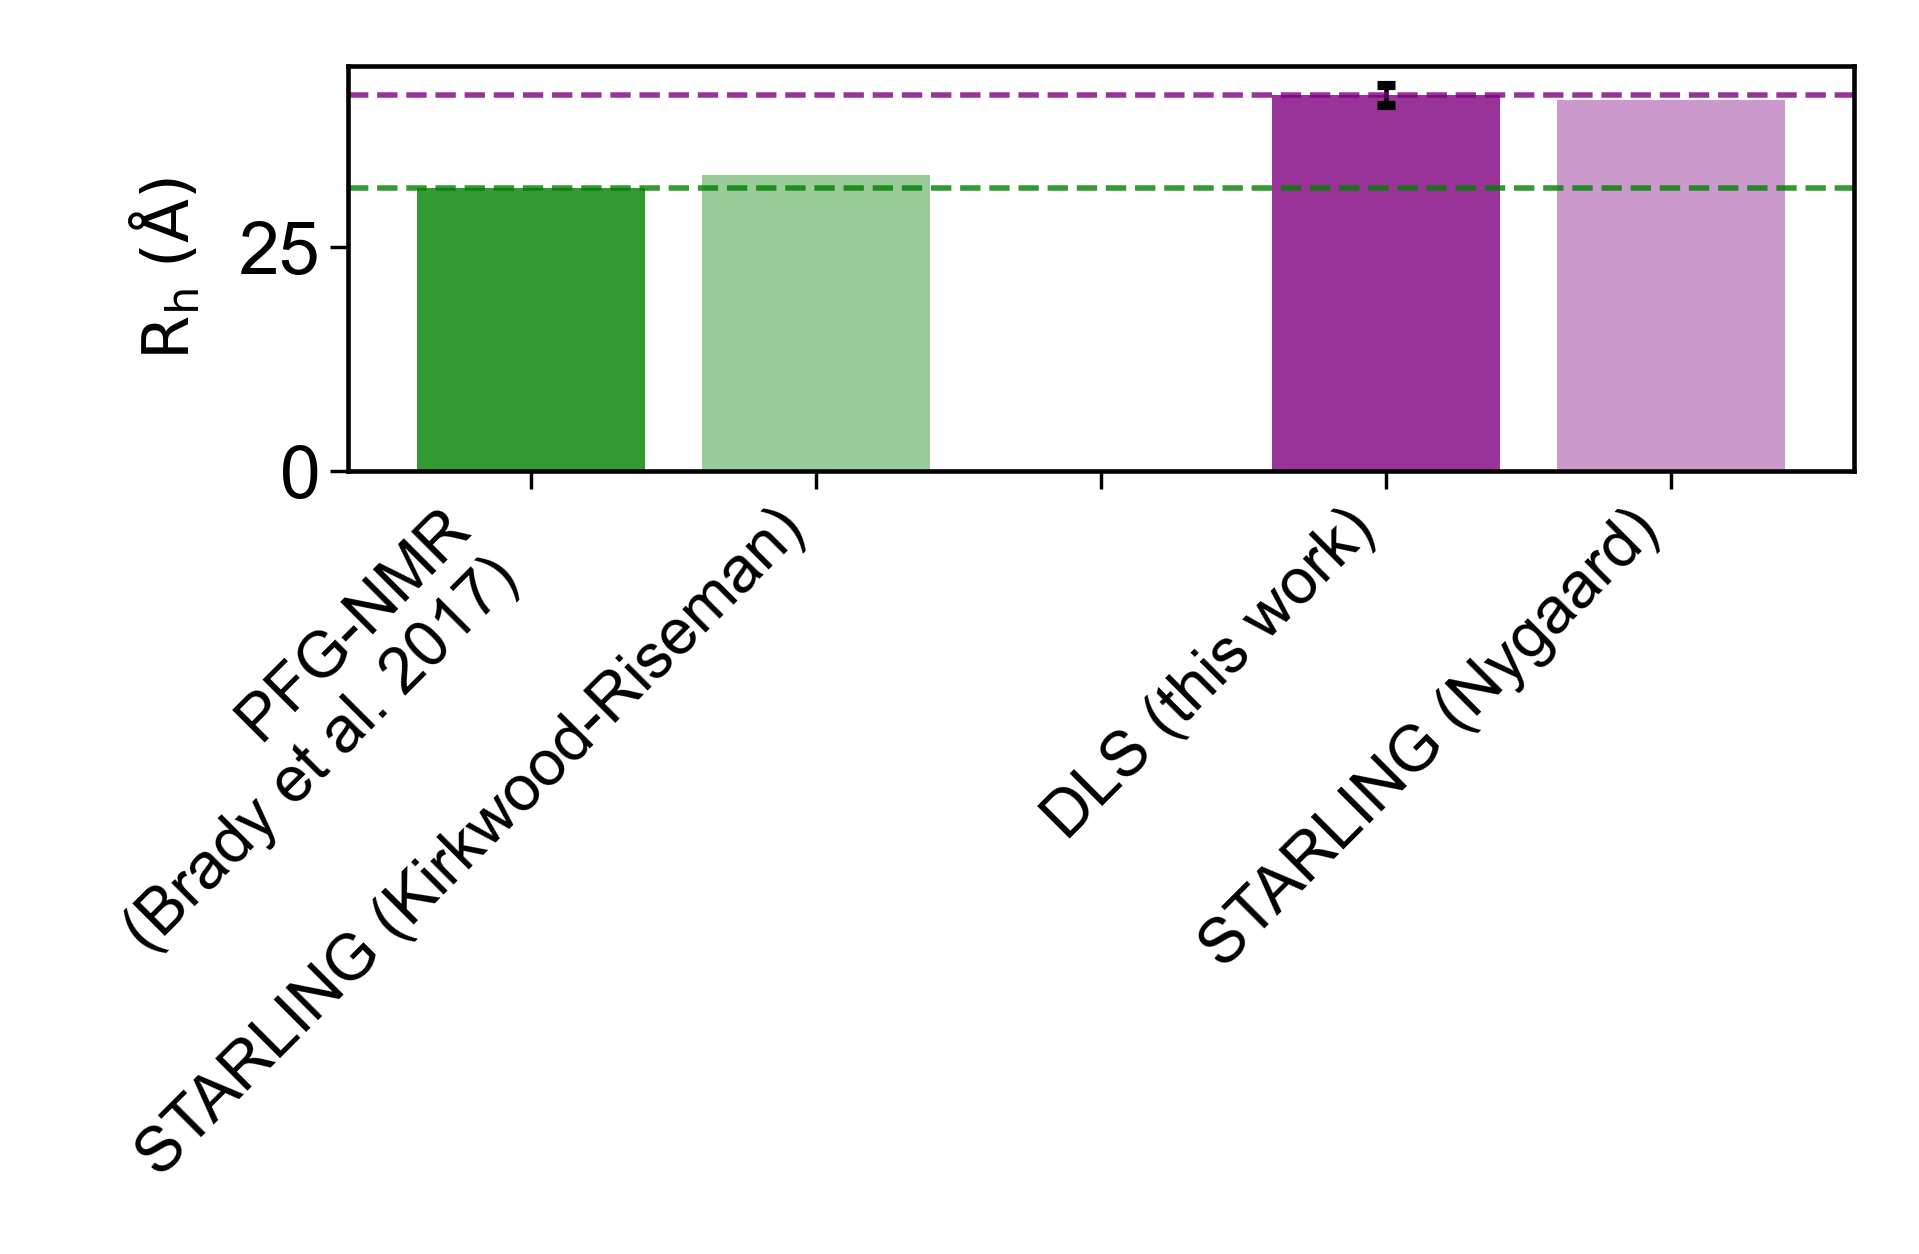

In [5]:
fig = plt.figure(figsize=(3, 2), dpi=330)
ax = plt.gca()

# green pair: PFG-NMR and the Kirkwood-Riseman prediction
ax.bar([1], [RH_PFG_NMR], color='g', alpha=0.8)
ax.bar([2], [mean_rh_kr], color='g', alpha=0.4)

# purple pair: DLS and the Nygaard prediction
ax.bar([4], [RH_DLS], color='purple', alpha=0.8)
ax.bar([5], [mean_rh_nygaard], color='purple', alpha=0.4)

ax.errorbar(4, RH_DLS, yerr=RH_DLS_ERROR, fmt='none', ecolor='k', capsize=1, linewidth=0.5)

ax.axhline(RH_PFG_NMR, color='g', alpha=0.8, ls='--', lw=0.6)
ax.axhline(RH_DLS, color='purple', alpha=0.8, ls='--', lw=0.6)

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(['PFG-NMR\n(Brady et al. 2017)',
                    'STARLING (Kirkwood-Riseman)',
                    '',
                    'DLS (this work)',
                    'STARLING (Nygaard)'],
                   rotation=45, ha='right', fontsize=7)

ax.set_ylabel(r'$\rm R_h\; (\rm\AA)$', fontsize=7)

plt.tight_layout()
plt.savefig('figures/figure_S8_rh_comparison.pdf')
plt.savefig('figures/figure_S8_rh_comparison.png', dpi=350)
plt.show()

## Differences from the published figure

* **Typesetting.** The published panel was restyled in a vector graphics editor - the axis frame, tick styling and label placement differ - but the four bar heights, the colours and the DLS error bar are as produced here.
* **Nothing else.** The values are computed live from the ensemble rather than transcribed, so the two STARLING bars will track any change in the underlying ensemble.